# Hussein Jawad

**CSCI E-89 Deep Learning – Homework 6**

# Problem 1

**Problem statement.** Plots of training data on slides 24 and 28 are actually from another
example and not from Géron's chapter 18 notebook. Use the following code to generate a new set
of 3D data `X_train`:

```python
import numpy as np
np.random.seed(4)
def generate_3d_data(m, w1=0.1, w2=0.3, noise=0.1):
    angles = np.random.rand(m) * 3 * np.pi / 2 - 0.5
    data = np.empty((m, 3))
    data[:, 0] = np.cos(angles) + np.sin(angles)/2 + noise * np.random.randn(m) / 2
    data[:, 1] = np.sin(angles) * 0.7 + noise * np.random.randn(m) / 2
    data[:, 2] = data[:, 0] * w1 + data[:, 1] * w2 + noise * np.random.randn(m)
    return data

X_train = generate_3d_data(60)
X_train = X_train - X_train.mean(axis=0, keepdims=0)
```

**Approach.** We train the linear autoencoder from slide 25 (`encoder = nn.Linear(3, 2)`,
`decoder = nn.Linear(2, 3)`) on this new `X_train` and reproduce the two plots from the slides
using this data:

* **slide 24:** the 3D training data, drawn with a 3D `scatter()` plot, and
* **slide 28:** the 2D `codings` output by the encoder (first hidden layer). The arc shape should
  match, but it may be rotated or flipped compared with the slide, because the autoencoder's
  coding axes can point in any direction within the best-fit (PCA) plane.

The code is based on Géron's chapter 18 notebook and the lecture slides, simplified to what
Problem 1 needs.

# Google Colab setup

Mount Google Drive so that the saved figures persist between Colab sessions.
(When the notebook is run outside Colab, the current folder is used instead.)

In [1]:
# %pip install torch matplotlib scikit-learn  # Uncomment once if the packages are missing.

import sys                                              # Access to the list of loaded modules.
from pathlib import Path                                # Path builds file paths that work on any OS.

IS_COLAB = "google.colab" in sys.modules                # True when running inside Google Colab.
if IS_COLAB:                                            # Only Colab can mount Google Drive.
    from google.colab import drive                      # Colab tool to connect your Google Drive.
    drive.mount('/content/drive')                       # Mount Google Drive (asks for permission the first time).
    PROJECT_DIR = Path('/content/drive/MyDrive/CSCI-E-89-1-Deep-Learning/HW06')  # Project folder in Google Drive; saved figures persist between Colab sessions.
else:                                                   # Running locally (e.g., Jupyter on a laptop).
    PROJECT_DIR = Path.cwd()                            # Use the notebook's current folder.
PROJECT_DIR.mkdir(parents=True, exist_ok=True)          # Create the folder; no error if it already exists.
print('Project folder:', PROJECT_DIR)                   # Show where outputs will be saved.

Project folder: /home/user/e89_Hussein_Jawad_HW06


# Setup

In [2]:
import numpy as np                                      # NumPy: arrays for generating and plotting the data.
import torch                                            # PyTorch: tensors, GPU support, and autograd.
from torch import nn                                    # Neural network layers and loss functions.
from torch.utils.data import DataLoader, TensorDataset  # Split the data into shuffled mini-batches.
import matplotlib.pyplot as plt                         # Plotting library.

device = "cuda" if torch.cuda.is_available() else "cpu" # Use the Colab GPU if one is available.
print("PyTorch:", torch.__version__, "| device:", device)  # Show the PyTorch version and device.

IMAGES_DIR = PROJECT_DIR / "images"                     # Folder for the saved figures.
IMAGES_DIR.mkdir(exist_ok=True)                         # Create it; no error if it already exists.

PyTorch: 2.14.1+cu130 | device: cpu


## Build the 3D dataset (code given in Problem 1)

In [3]:
np.random.seed(4)                                       # Reproducible dataset.

def generate_3d_data(m, w1=0.1, w2=0.3, noise=0.1):
    angles = np.random.rand(m) * 3 * np.pi / 2 - 0.5    # Random angles in [-0.5, 3π/2 - 0.5).
    data = np.empty((m, 3))                             # Allocate an m x 3 array.
    data[:, 0] = np.cos(angles) + np.sin(angles)/2 + noise * np.random.randn(m) / 2  # x1: curved + noise.
    data[:, 1] = np.sin(angles) * 0.7 + noise * np.random.randn(m) / 2  # x2: curved + noise.
    data[:, 2] = data[:, 0] * w1 + data[:, 1] * w2 + noise * np.random.randn(m)  # x3: near plane w1*x1 + w2*x2.
    return data                                         # Return the 3D dataset.

X_train = generate_3d_data(60)                          # 60 training instances.
X_train = X_train - X_train.mean(axis=0, keepdims=0)    # Center the data (PCA assumes centered data).
print(X_train.shape)                                    # (60, 3): 60 vectors of dimension 3.

(60, 3)


## Visualize the data (slide 24)

A 3D scatter plot of the 60 training points:

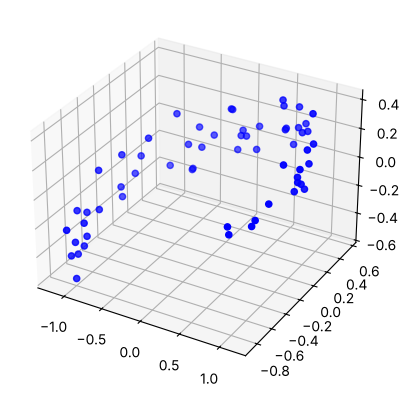

In [4]:
fig = plt.figure()                                      # New figure.
ax = fig.add_subplot(111, projection="3d")              # 3D axes.
ax.scatter(X_train[:, 0], X_train[:, 1], X_train[:, 2], c="b", marker="o")  # One blue dot per point.
plt.savefig(IMAGES_DIR / "problem1_3d_training_data.png", dpi=300)  # Save the figure (to Drive in Colab).
plt.show()                                              # Display the figure.

## Build the autoencoder (slide 25)

The encoder and the decoder are each a single `nn.Linear` layer, chained with `nn.Sequential`.
The model has 3 inputs, a 2D coding layer, and 3 outputs. To perform PCA we use **no activation
function** (all neurons are linear) and the **MSE** loss.

In [5]:
torch.manual_seed(42)                                   # Reproducible weight initialization.
encoder = nn.Linear(3, 2)                               # Encoder: 3D inputs -> 2D codings.
decoder = nn.Linear(2, 3)                               # Decoder: 2D codings -> 3D reconstructions.
autoencoder = nn.Sequential(encoder, decoder).to(device)  # Chain encoder and decoder; move to the GPU.

## Train the autoencoder

The same data, `X_train`, is both the input and the target: the autoencoder learns to
reconstruct its own input through the 2D bottleneck.

We use the NAdam optimizer (as in Géron's notebook) with lr=0.02, and train for 100 epochs in
mini-batches of 32. The loss reaches the PCA optimum after about 40 epochs; the extra epochs are
a safety margin.

In [6]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)  # NumPy array -> PyTorch tensor (float32).
train_loader = DataLoader(TensorDataset(X_train_t), batch_size=32, shuffle=True)  # Shuffled mini-batches of 32.

optimizer = torch.optim.NAdam(autoencoder.parameters(), lr=0.02)  # Optimizer that updates the weights.
loss_fn = nn.MSELoss()                                  # Reconstruction error: mean squared error.
n_epochs = 100                                          # Number of passes over the training data.
losses = []                                             # Mean loss of each epoch (learning curve).

for epoch in range(n_epochs):                           # Loop over the epochs.
    total_loss = 0.0                                    # Sum of the losses in this epoch.
    for (X_batch,) in train_loader:                     # Loop over the mini-batches.
        X_batch = X_batch.to(device)                    # Move the batch to the GPU.
        X_rec = autoencoder(X_batch)                    # Forward pass: reconstruct the inputs.
        loss = loss_fn(X_rec, X_batch)                  # Compare reconstructions with the inputs.
        optimizer.zero_grad()                           # Reset the gradients from the previous step.
        loss.backward()                                 # Backpropagation: compute the gradients.
        optimizer.step()                                # Update the weights.
        total_loss += loss.item() * len(X_batch)        # Add this batch's loss (weighted by its size).
    losses.append(total_loss / len(X_train_t))          # Mean loss over the epoch.
    if (epoch + 1) % 10 == 0:                           # Print every 10 epochs.
        print(f"Epoch {epoch + 1}/{n_epochs}: loss={losses[-1]:.4f}")

Epoch 10/100: loss=0.0760
Epoch 20/100: loss=0.0428
Epoch 30/100: loss=0.0118
Epoch 40/100: loss=0.0036
Epoch 50/100: loss=0.0035
Epoch 60/100: loss=0.0035
Epoch 70/100: loss=0.0034
Epoch 80/100: loss=0.0035
Epoch 90/100: loss=0.0034


Epoch 100/100: loss=0.0036


Learning curve (log scale), showing the convergence:

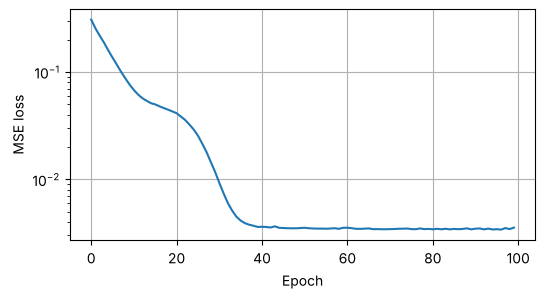

In [7]:
plt.figure(figsize=(6, 3))                              # New figure.
plt.semilogy(losses)                                    # Training loss per epoch, log scale.
plt.xlabel("Epoch")                                     # x-axis label.
plt.ylabel("MSE loss")                                  # y-axis label.
plt.grid(True)                                          # Add a grid.
plt.show()                                              # Display the figure.

## `codings`, outputs of the first hidden layer (slide 28)

No `Linear` layer is followed by a non-linear unit. We trained with 60 vectors of dimension 3,
so the encoder (first hidden layer) produces 60 vectors of dimension 2 (`codings`):

In [8]:
with torch.no_grad():                                   # Just using the model: no gradients needed.
    codings = encoder(X_train_t.to(device))             # Run only the encoder: 3D -> 2D.
codings = codings.cpu().numpy()                         # Back to the CPU as a NumPy array for plotting.
print(codings.shape)                                    # (60, 2): 60 vectors of dimension 2.

(60, 2)


Plot the 2D codings:

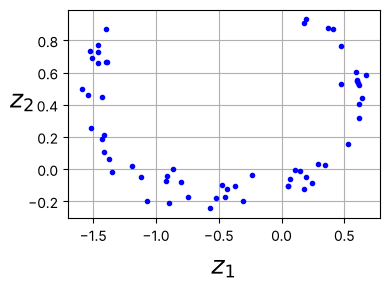

In [9]:
plt.figure(figsize=(4, 3))                              # New figure.
plt.plot(codings[:, 0], codings[:, 1], "b.")            # One blue dot per coding.
plt.xlabel("$z_1$", fontsize=18)                        # First coding dimension.
plt.ylabel("$z_2$", fontsize=18, rotation=0)            # Second coding dimension.
plt.grid(True)                                          # Add a grid.
plt.tight_layout()                                      # Avoid cutting off the axis labels.
plt.savefig(IMAGES_DIR / "problem1_codings_2d.png", dpi=300)  # Save the figure (to Drive in Colab).
plt.show()                                              # Display the figure.

## Check: is this really PCA?

The best possible linear 2D reconstruction is the PCA one, so the autoencoder's reconstruction
error should match it:

In [10]:
from sklearn.decomposition import PCA                   # Scikit-Learn's PCA.

pca = PCA(n_components=2)                               # Keep the top 2 principal components.
X_pca_rec = pca.inverse_transform(pca.fit_transform(X_train))  # Project to 2D, then back to 3D.

with torch.no_grad():                                   # Just using the model: no gradients needed.
    X_ae_rec = autoencoder(X_train_t.to(device)).cpu().numpy()  # Autoencoder: 3D -> 2D -> 3D.

print(f"PCA reconstruction MSE:         {np.mean((X_train - X_pca_rec) ** 2):.5f}")  # Best possible linear error.
print(f"Autoencoder reconstruction MSE: {np.mean((X_train - X_ae_rec) ** 2):.5f}")   # Should be nearly equal.

PCA reconstruction MSE:         0.00339
Autoencoder reconstruction MSE: 0.00342


**Observation:** the 3D training data lies close to the plane $x_3 \approx 0.1x_1 + 0.3x_2$, curved
into an arc. The 2D codings keep that arc shape and drop only the low-variance direction (mostly
the noise off the plane). The autoencoder's reconstruction error matches PCA's, so it found the
best 2D plane to project the data onto: the plane that keeps the largest variance. Its coding
axes $z_1, z_2$ need not be the principal components themselves (they can be rotated, scaled
or skewed within that plane), which is why the arc may look rotated or stretched compared with
a PCA plot.